<a href="https://colab.research.google.com/github/alinelima1909/Atividade-notas-dos-alunos_desafio1_python-colab/blob/main/Mapareconecimentodepadroes15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Imersão Reconhecimento de padrões MAPA

PARTE 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt



In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
file_path = '/content/dados_mapareconhecimentodepadroes.csv'
df = pd.read_csv(file_path)
display(df.head())

,Cliente,Idade,Gênero,Categoria Produto,Valor (R$),Data Compra,Hora Compra,Canal,Cidade,Estado
0,C001,58,M,Cosméticos,2603.18,2025-05-22,11:42,App Mobile,Fogaça de Lima,PA
1,C002,32,M,Eletrodomésticos,2378.15,2025-05-05,03:12,Web Site,Nogueira da Serra,RO
2,C003,23,F,Cosméticos,133.40,2025-05-09,22:14,App Mobile,da Cunha,AL
3,C004,32,M,Calçados,719.97,2025-05-17,03:02,Web Site,Cavalcanti,ES
4,C005,62,F,TV e Som,1588.76,2025-05-12,23:30,Loja Física,Nogueira,DF


Verificando quantidade de colunasx linhas,  tipos de variaveis e valores ausentes

In [15]:
df.shape

(100, 10)

In [16]:
df.info

<bound method DataFrame.info of    Cliente  Idade Gênero Categoria Produto  Valor (R$) Data Compra  \
0     C001     58      M        Cosméticos     2603.18  2025-05-22   
1     C002     32      M  Eletrodomésticos     2378.15  2025-05-05   
2     C003     23      F        Cosméticos      133.40  2025-05-09   
3     C004     32      M          Calçados      719.97  2025-05-17   
4     C005     62      F          TV e Som     1588.76  2025-05-12   
..     ...    ...    ...               ...         ...         ...   
95    C096     55      F        Acessórios     1563.00  2025-05-02   
96    C097     31      F            Livros     2316.21  2025-04-28   
97    C098     50      F  Eletrodomésticos     2869.93  2025-05-02   
98    C099     61      F          TV e Som     2828.77  2025-05-12   
99    C100     19      M          TV e Som     3444.26  2025-05-14   

   Hora Compra        Canal             Cidade Estado  
0        11:42   App Mobile     Fogaça de Lima     PA  
1        03:12     Web Site  Nogueira da Serra     RO  
2        22:14   App Mobile           da Cunha     AL  
3        03:02     Web Site         Cavalcanti     ES  
4        23:30  Loja Física           Nogueira     DF  
..         ...          ...                ...    ...  
95       04:43     Web Site     da Mata Grande     AC  
96       03:11  Loja Física           Nogueira     PE  
97       00:23   App Mobile              Porto     RS  
98       17:37   App Mobile   Farias do Amparo     SP  
99       00:11     Web Site    Caldeira Grande     RO  

[100 rows x 10 columns]>

In [17]:
df.isnull().sum()

,0
Cliente,0
Idade,0
Gênero,0
Categoria Produto,0
Valor (R$),0
Data Compra,0
Hora Compra,0
Canal,0
Cidade,0
Estado,0


**Faixa Etária: conforme a atividade fornece**

In [21]:
def faixa_etaria(idade):
   if idade<30:
     return 'Jovem'
   elif idade<=45:
     return 'Adulto'
   else:
     return 'Senior'

df['faixa_etaria']= df['Idade'].apply(faixa_etaria)

In [22]:
df['faixa_etaria'].value_counts()

,count
faixa_etaria,
Senior,40
Adulto,30
Jovem,30


***Canais por faixa etária***

In [23]:
pd.crosstab(df['faixa_etaria'], df['Canal'])

Canal,App Mobile,Loja Física,Web Site
faixa_etaria,,,
Adulto,8,10,12
Jovem,11,11,8
Senior,17,13,10


**Cidade e Estado**

In [25]:
df.groupby(['Estado', 'Cidade']).size()

Estado  Cidade          
AC      Barbosa do Sul      1
        Vieira              1
        da Mata Grande      1
AL      Gonçalves Verde     1
        Martins             1
                           ..
SP      Araújo              1
        Azevedo             1
        Farias do Amparo    1
        das Neves           1
TO      Aragão de Goiás     1
Length: 100, dtype: int64

**Compras por Estado**

In [27]:
from numpy import False_
df.groupby('Estado').size().sort_values(ascending=False)

,0
Estado,
RN,7
PE,7
GO,6
RO,6
DF,6
AP,6
SE,6
RS,5
ES,4


*ETAPA 2- Identificação de Padrões*

In [28]:
pd.crosstab(df["Gênero"], df["Categoria Produto"])

Categoria Produto,Acessórios,Calçados,Celulares,Cosméticos,Eletrodomésticos,Games,Livros,Roupas,Suplementos,TV e Som
Gênero,,,,,,,,,,
F,6,6,2,5,5,6,5,4,3,7
M,2,8,5,4,4,4,2,7,7,8


In [29]:
pd.crosstab(df["Gênero"], df["Categoria Produto"]).idxmax(axis=1)

,0
Gênero,
F,TV e Som
M,Calçados


<Axes: xlabel='Gênero'>

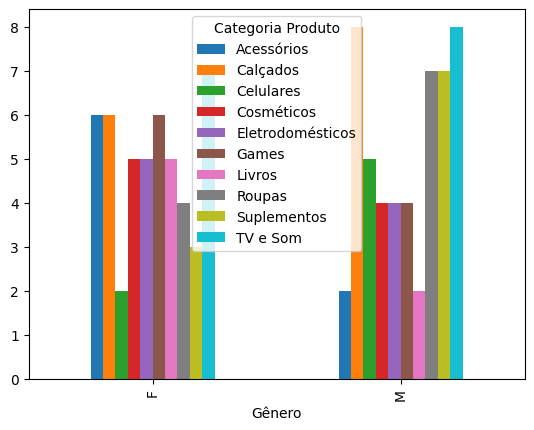

In [30]:
pd.crosstab(df["Gênero"], df["Categoria Produto"]).plot(kind="bar")

***Etapa 3 — Faixa etária × Categoria de Produto

In [32]:
pd.crosstab(df["faixa_etaria"], df["Categoria Produto"])

Categoria Produto,Acessórios,Calçados,Celulares,Cosméticos,Eletrodomésticos,Games,Livros,Roupas,Suplementos,TV e Som
faixa_etaria,,,,,,,,,,
Adulto,1,4,1,1,5,2,2,4,4,6
Jovem,4,5,4,3,0,4,2,2,3,3
Senior,3,5,2,5,4,4,3,5,3,6


In [33]:
pd.crosstab(df["faixa_etaria"], df["Categoria Produto"]).idxmax(axis=1)

,0
faixa_etaria,
Adulto,TV e Som
Jovem,Calçados
Senior,TV e Som


*Estado x Quantidade de Compras*

In [34]:
compras_estado = df["Estado"].value_counts()

compras_estado

,count
Estado,
RN,7
PE,7
GO,6
SE,6
RO,6
DF,6
AP,6
RS,5
ES,4


In [35]:
compras_estado.sort_values(ascending=False)

,count
Estado,
RN,7
PE,7
GO,6
SE,6
RO,6
DF,6
AP,6
RS,5
ES,4


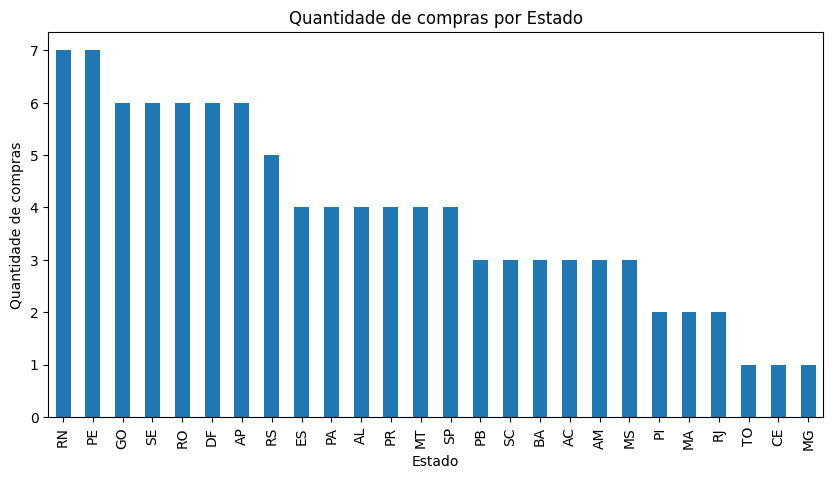

In [36]:
compras_estado.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Quantidade de compras por Estado")
plt.xlabel("Estado")
plt.ylabel("Quantidade de compras")
plt.show()

***Etapa 5 — Horário × comportamento de compra***

In [37]:
df["Hora"] = pd.to_datetime(
    df["Hora Compra"],
    format="%H:%M"
).dt.hour

In [38]:
def periodo_dia(hora):
    if 5 <= hora < 12:
        return "Manhã"
    elif 12 <= hora < 18:
        return "Tarde"
    else:
        return "Noite"

df["Período"] = df["Hora"].apply(periodo_dia)

In [39]:
df["Período"].value_counts()

,count
Período,
Noite,47
Tarde,28
Manhã,25


In [40]:
df.groupby("Período")["Valor (R$)"].sum()

,Valor (R$)
Período,
Manhã,36798.93
Noite,79307.38
Tarde,48490.90


In [41]:
df.groupby("Período")["Valor (R$)"].mean()

,Valor (R$)
Período,
Manhã,1471.957200
Noite,1687.391064
Tarde,1731.817857


**Etapa 6: Faixa Etária x Valor Gasto**

In [43]:
df.groupby("faixa_etaria")["Valor (R$)"].mean()

,Valor (R$)
faixa_etaria,
Adulto,1738.982000
Jovem,1520.324333
Senior,1670.450500


In [45]:
df.groupby("faixa_etaria")["Valor (R$)"].sum()

,Valor (R$)
faixa_etaria,
Adulto,52169.46
Jovem,45609.73
Senior,66818.02


***Etapa 7: Estado x Valor Total

In [46]:
df.groupby("Estado")["Cliente"].count().sort_values(ascending=False)

,Cliente
Estado,
RN,7
PE,7
GO,6
RO,6
DF,6
AP,6
SE,6
RS,5
ES,4


In [47]:
df.groupby("Estado")["Cliente"].count().sort_values(ascending=False)

,Cliente
Estado,
RN,7
PE,7
GO,6
RO,6
DF,6
AP,6
SE,6
RS,5
ES,4
